# SaúdeScope
## Notebook 01 — Ingestão e Leitura dos Microdados da PNS 2019

**Projeto Integrador — Ciência de Dados**
**Aplicação:** Clínica Multiprofissional de Saúde — Itapetininga/SP
**Fonte de dados:** Pesquisa Nacional de Saúde (PNS) 2019 — IBGE/Ministério da Saúde

---


## 1. Contexto e objetivo deste notebook

Este é o primeiro notebook do projeto **SaúdeScope**. Antes de qualquer análise ou modelo,
precisamos resolver um problema bem prático: **os microdados da PNS não vêm em um formato
pronto para uso** (como um `.csv`), e sim em um arquivo de **largura fixa** (`fixed-width file`),
um padrão histórico usado por institutos de estatística como o IBGE.

O objetivo deste notebook é:

1. Entender e automatizar a leitura do layout do arquivo (que vem descrito em um script SAS);
2. Selecionar, de forma justificada, as variáveis relevantes para o problema de negócio da clínica;
3. Ler o arquivo bruto de ~293 mil registros e ~1.550 variáveis, extraindo apenas o recorte que
   interessa ao projeto;
4. Validar a qualidade da leitura (checagens de consistência);
5. Aplicar o primeiro filtro de escopo (Estado de São Paulo + entrevistas efetivamente realizadas);
6. Exportar um dataset intermediário, limpo na estrutura (ainda não no conteúdo), para ser
   consumido pelo próximo notebook (`02_limpeza_e_tratamento.ipynb`), que fará a parte de
   recodificação de categorias, tratamento de valores ausentes e engenharia de variáveis
   (ex.: cálculo de IMC, faixas etárias).

> **Por que começar assim, e não já "pulando" para a análise?**
> Porque a qualidade de qualquer modelo de Machine Learning ou painel de BI depende
> diretamente da confiabilidade da base que os alimenta. Um erro de leitura de posição de
> coluna nesta etapa se propagaria silenciosamente por todo o projeto — por isso investimos
> tempo em automatizar e validar essa leitura, em vez de simplesmente "copiar posições" à mão.


## 2. Sobre a fonte de dados

A PNS é considerada a pesquisa de saúde mais completa do Brasil, realizada pelo IBGE em parceria
com o Ministério da Saúde. A edição usada neste projeto é a de **2019** (última edição com
microdados completos disponíveis — a edição 2023-2026 ainda está em campo).

**Estrutura do arquivo bruto (`PNS_2019.txt`):**

| Característica | Valor |
|---|---|
| Formato | Texto de largura fixa (sem cabeçalho, sem delimitador) |
| Tamanho do arquivo | ~455 MB |
| Registros (linhas) | 293.726 |
| Tamanho de cada registro | 1.548 caracteres |
| Unidade de observação | Pessoa (morador do domicílio) |

Cada variável ocupa uma posição fixa de caracteres dentro da linha. O mapeamento de qual
variável está em qual posição vem no arquivo `input_PNS_2019.sas`, fornecido pelo próprio IBGE.

**Identificação de registros** (conforme documentação oficial do IBGE):
- Chave de domicílio: `V0001 + V0024 + UPA_PNS + V0006_PNS`
- Chave de pessoa: `V0001 + V0024 + UPA_PNS + V0006_PNS + C00301`

Essas chaves servem apenas para identificar um registro *dentro* da base 2019 — não devem ser
usadas para comparações longitudinais com outras edições da pesquisa.


In [1]:
# Bibliotecas utilizadas neste notebook
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)

# Caminhos do projeto
RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SAS_LAYOUT_PATH = RAW_DIR / "input_PNS_2019.sas"
DATA_PATH = RAW_DIR / "PNS_2019.txt"

print("Arquivo de layout:", SAS_LAYOUT_PATH, "-", SAS_LAYOUT_PATH.stat().st_size, "bytes")
print("Arquivo de dados :", DATA_PATH, "-", round(DATA_PATH.stat().st_size / 1e6, 1), "MB")


Arquivo de layout: data/raw/input_PNS_2019.sas - 23595 bytes
Arquivo de dados : data/raw/PNS_2019.txt - 455.3 MB


## 3. Parser do layout SAS

Em vez de copiar manualmente a posição de cada variável (o que seria inviável e propenso a
erro, considerando que o layout tem mais de mil variáveis), escrevemos uma função que **lê o
próprio script SAS fornecido pelo IBGE e extrai automaticamente**: nome da variável, posição
inicial, tamanho, tipo (texto ou numérico) e casas decimais implícitas.

Essa abordagem tem uma vantagem direta para o projeto: se no futuro quisermos incluir mais
variáveis da PNS na análise, basta adicionar o nome à lista de variáveis de interesse — não é
necessário procurar manualmente a posição no arquivo.


In [2]:
def parse_sas_layout(sas_path: Path) -> pd.DataFrame:
    """Lê o script de leitura em SAS dos microdados da PNS e retorna um
    DataFrame com o layout posicional de cada variável.

    Formatos possíveis encontrados no arquivo original, à direita do nome da
    variável:
        $2.     -> variável de texto, largura 2
        3.      -> variável numérica inteira, largura 3
        5.1     -> variável numérica, largura 5, com 1 casa decimal implícita
        14.8    -> variável numérica, largura 14, com 8 casas decimais implícitas

    As casas decimais "implícitas" existem porque, no arquivo de largura fixa,
    não há ponto decimal gravado: o valor precisa ser dividido por 10**decimais
    depois da leitura.
    """
    texto = sas_path.read_text(encoding="latin1")

    padrao = re.compile(r"@(\d+)\s+([A-Za-z0-9_]+)\s+(\$)?(\d+)(?:\.(\d+))?\.?")

    registros = []
    for pos, nome, eh_texto, largura, decimais in padrao.findall(texto):
        registros.append({
            "variavel": nome,
            "posicao_inicial": int(pos),
            "tamanho": int(largura),
            "tipo": "texto" if eh_texto else "numerico",
            "decimais": int(decimais) if decimais else 0,
        })

    layout = (
        pd.DataFrame(registros)
        .drop_duplicates(subset="variavel")
        .reset_index(drop=True)
    )
    layout["posicao_final"] = layout["posicao_inicial"] + layout["tamanho"] - 1
    return layout


layout = parse_sas_layout(SAS_LAYOUT_PATH)
print(f"Total de variáveis mapeadas no layout: {len(layout)}")
layout.head(10)


Total de variáveis mapeadas no layout: 1088


,variavel,posicao_inicial,tamanho,tipo,decimais,posicao_final
0,V0001,1,2,texto,0,2
1,V0024,3,7,texto,0,9
2,UPA_PNS,10,9,texto,0,18
3,V0006_PNS,19,4,texto,0,22
4,V0015,23,2,texto,0,24
5,V0020,25,4,texto,0,28
6,V0022,29,2,numerico,0,30
7,V0026,31,1,texto,0,31
8,V0031,32,1,texto,0,32
9,V0025A,33,1,texto,0,33


In [3]:
# Checagem de consistência: a última posição do layout deve bater exatamente
# com o tamanho de registro declarado no INFILE do script SAS (LRECL=1548)
tamanho_registro_esperado = 1548
maior_posicao = layout["posicao_final"].max()

assert maior_posicao == tamanho_registro_esperado, (
    f"Inconsistência no layout: posição final máxima ({maior_posicao}) "
    f"difere do LRECL esperado ({tamanho_registro_esperado})"
)
print(f"OK — layout consistente: última posição mapeada = {maior_posicao} (esperado {tamanho_registro_esperado})")


OK — layout consistente: última posição mapeada = 1548 (esperado 1548)


## 4. Seleção das variáveis de interesse

A PNS 2019 tem mais de mil variáveis, cobrindo desde saneamento básico até mercado de trabalho.
Para este projeto, selecionamos apenas o recorte que se conecta diretamente às especialidades
oferecidas pela clínica parceira, evitando o que se chamaria de "dragagem de dados" (selecionar
variáveis sem critério e só depois procurar relação com o problema).

| Variável | Descrição | Por que interessa à clínica |
|---|---|---|
| `V0001` | Unidade da Federação | Permite isolar o recorte de São Paulo |
| `V0024`, `UPA_PNS`, `V0006_PNS` | Compõem a chave de domicílio | Identificação técnica do registro |
| `V0015` | Resultado da entrevista | Filtrar apenas entrevistas efetivamente realizadas |
| `C00301` | Compõe a chave de pessoa | Identificação técnica do registro |
| `C006` | Sexo | Variável de segmentação |
| `C008` | Idade do morador | Variável central — a clínica atende "todas as etapas da vida" |
| `C009` | Cor ou raça | Variável de contexto sociodemográfico |
| `VDD004A` | Nível de instrução | Variável de contexto socioeconômico |
| `Q00201` | Diagnóstico de hipertensão | Relevante para nutrição clínica e fisioterapia |
| `Q03001` | Diagnóstico de diabetes | Relevante para nutrição clínica |
| `Q068` | Diagnóstico de AVC/derrame | Relevante para fisioterapia (quiropraxia/reabilitação) |
| `Q092` | Diagnóstico de depressão | Relevante para as 6 psicólogas da clínica |
| `Q11006` | Diagnóstico de outra doença mental (ansiedade, bipolaridade, esquizofrenia etc.) | Relevante para as psicólogas |
| `Q124` | Diagnóstico de insuficiência renal crônica | Relevante para a especialidade do nutricionista em doença renal |
| `P00403`, `P00404` | Altura informada (cm) | Insumo para cálculo de IMC (fallback) |
| `W00103` | Peso aferido pelo entrevistador (kg) | Insumo para cálculo de IMC (medida mais confiável) |
| `W00203` | Altura aferida pelo entrevistador (cm) | Insumo para cálculo de IMC (medida mais confiável) |
| `V00281` | Peso amostral calibrado | Necessário para qualquer estimativa populacional correta |

> **Nota metodológica importante:** a PNS é uma pesquisa amostral complexa, não um censo. Isso
> significa que cada pessoa entrevistada "representa" um número diferente de pessoas na
> população. Por isso a variável de **peso amostral (`V00281`)** é obrigatória em qualquer
> cálculo de prevalência que temos intenção de generalizar — usaremos essa variável a partir
> do notebook de análise exploratória.


In [4]:
variaveis_interesse = {
    # --- Identificação e recorte geográfico ---
    "V0001":     "Unidade da Federação",
    "V0024":     "Estrato (chave de domicílio)",
    "UPA_PNS":   "Unidade Primária de Amostragem (chave de domicílio)",
    "V0006_PNS": "Número de ordem do domicílio (chave de domicílio)",
    "V0015":     "Resultado da entrevista",
    "C00301":    "Número de ordem do morador (chave de pessoa)",

    # --- Perfil demográfico ---
    "C006":      "Sexo",
    "C008":      "Idade do morador (anos)",
    "C009":      "Cor ou raça",
    "VDD004A":   "Nível de instrução mais elevado",

    # --- Doenças crônicas (Módulo Q) ---
    "Q00201":    "Diagnóstico de hipertensão arterial",
    "Q03001":    "Diagnóstico de diabetes",
    "Q068":      "Diagnóstico de AVC/derrame",
    "Q092":      "Diagnóstico de depressão",
    "Q11006":    "Diagnóstico de outra doença mental",
    "Q124":      "Diagnóstico de insuficiência renal crônica",

    # --- Antropometria (para IMC / obesidade) ---
    "P00403":    "Altura informada (cm)",
    "P00404":    "Altura informada - final (cm)",
    "W00103":    "Peso aferido - final (kg)",
    "W00203":    "Altura aferida - final (cm)",

    # --- Peso amostral ---
    "V00281":    "Peso amostral calibrado",
}

subset_layout = (
    layout[layout["variavel"].isin(variaveis_interesse)]
    .sort_values("posicao_inicial")
    .reset_index(drop=True)
)

faltando = set(variaveis_interesse) - set(subset_layout["variavel"])
print(f"Variáveis de interesse encontradas no layout: {len(subset_layout)} de {len(variaveis_interesse)}")
if faltando:
    print("ATENÇÃO — variáveis não localizadas no layout:", faltando)
else:
    print("Todas as variáveis de interesse foram localizadas com sucesso.")

subset_layout


Variáveis de interesse encontradas no layout: 21 de 21
Todas as variáveis de interesse foram localizadas com sucesso.


,variavel,posicao_inicial,tamanho,tipo,decimais,posicao_final
0,V0001,1,2,texto,0,2
1,V0024,3,7,texto,0,9
2,UPA_PNS,10,9,texto,0,18
3,V0006_PNS,19,4,texto,0,22
4,V0015,23,2,texto,0,24
5,C00301,104,2,texto,0,105
6,C006,108,1,texto,0,108
7,C008,117,3,numerico,0,119
8,C009,120,1,texto,0,120
9,P00403,614,3,numerico,0,616


## 5. Leitura do arquivo de largura fixa

Com as posições confirmadas, construímos os `colspecs` (pares de posição inicial/final,
no formato que o `pandas` espera) e lemos apenas as colunas selecionadas — sem carregar as mais
de mil variáveis que não usaremos, o que economiza tempo e memória.


In [5]:
colspecs = [
    (int(row.posicao_inicial - 1), int(row.posicao_final))
    for row in subset_layout.itertuples()
]
nomes_colunas = subset_layout["variavel"].tolist()

df_bruto = pd.read_fwf(
    DATA_PATH,
    colspecs=colspecs,
    names=nomes_colunas,
    dtype=str,          # lemos tudo como texto primeiro; convertemos tipos na próxima etapa
    encoding="latin1",
)

print("Formato do dataset lido:", df_bruto.shape)
df_bruto.head()


Formato do dataset lido: (293726, 21)


,V0001,V0024,UPA_PNS,V0006_PNS,V0015,C00301,C006,C008,C009,P00403,P00404,Q00201,Q03001,Q068,Q092,Q11006,Q124,W00103,W00203,V00281,VDD004A
0,11,1110011,110000016,0001,01,01,2,055,1,145,145,1,2,2,1,2,2,NaN,NaN,00118.31182322,2
1,11,1110011,110000016,0001,01,02,1,069,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,00118.31182322,1
2,11,1110011,110000016,0001,01,03,1,031,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,00118.31182322,5
3,11,1110011,110000016,0001,01,04,1,009,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,00118.31182322,1
4,11,1110011,110000016,0001,01,05,2,006,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,00118.31182322,1


## 6. Tratamento de tipos

Cada variável precisa ser convertida para o tipo correto:

- **Texto/categórica** (ex.: `V0001`, `Q00201`): mantemos como string, com espaços em branco
  tratados como valor ausente (`NaN`).
- **Numérica inteira** (ex.: `C008` — idade): convertida para inteiro.
- **Numérica com casas decimais** (ex.: `W00103`, `V00281`): aqui há um detalhe importante do
  formato SAS que vale registrar. O informat `w.d` (largura.decimais) só implica *dividir por
  `10**d`* quando o texto bruto **não** contém um ponto decimal. Quando o ponto já vem gravado
  explicitamente no arquivo (ex.: o campo de `V00281` contém literalmente `"00118.31182322"`),
  o valor deve ser lido tal como está, sem qualquer divisão. Confirmamos isso inspecionando o
  conteúdo bruto do arquivo antes de implementar a conversão — tratar os dois casos da mesma
  forma faria variáveis como o peso amostral saírem com um fator de escala errado por 10⁸,
  o que só seria percebido (se percebido) muito mais adiante, ao notar uma prevalência
  ponderada absurda. Por isso a função abaixo decide a conversão **valor a valor**, verificando
  a presença do ponto decimal em cada célula.


In [6]:
def converter_tipos(df: pd.DataFrame, layout_subset: pd.DataFrame) -> pd.DataFrame:
    """Converte cada coluna do DataFrame lido como texto para o tipo correto,
    de acordo com o que foi identificado no layout (texto, numérico inteiro
    ou numérico com casas decimais implícitas).

    Ponto de atenção (comportamento do informat SAS "w.d"): quando o valor
    bruto já contém um ponto decimal explícito no texto (ex.: "00118.31182322"),
    ele deve ser interpretado literalmente. A divisão por 10**decimais só se
    aplica quando o ponto NÃO está presente no texto bruto (decimal implícito).
    Tratar os dois casos da mesma forma faz variáveis como o peso amostral
    (V00281) e o peso/altura aferidos (W00103, W00203) saírem com um fator de
    escala completamente errado — por isso essa checagem é feita valor a valor.
    """
    df = df.copy()
    layout_idx = layout_subset.set_index("variavel")

    for coluna in df.columns:
        info = layout_idx.loc[coluna]
        serie = df[coluna].str.strip()
        serie = serie.replace("", np.nan)

        if info["tipo"] == "numerico":
            if info["decimais"] > 0:
                tem_ponto = serie.str.contains(r"\.", na=False)
                valores = pd.Series(np.nan, index=serie.index, dtype="float64")
                # Ponto decimal já explícito no texto bruto: interpretar literalmente
                valores.loc[tem_ponto] = pd.to_numeric(serie[tem_ponto], errors="coerce")
                # Decimal implícito (sem ponto no texto): dividir pelo fator do layout
                sem_ponto = ~tem_ponto
                valores.loc[sem_ponto] = (
                    pd.to_numeric(serie[sem_ponto], errors="coerce") / (10 ** info["decimais"])
                )
                df[coluna] = valores
            else:
                df[coluna] = pd.to_numeric(serie, errors="coerce").astype("Int64")
        else:
            df[coluna] = serie

    return df


df = converter_tipos(df_bruto, subset_layout)
df.dtypes


V0001            str
V0024            str
UPA_PNS          str
V0006_PNS        str
V0015            str
C00301           str
C006             str
C008           Int64
C009             str
P00403         Int64
P00404         Int64
Q00201           str
Q03001           str
Q068             str
Q092             str
Q11006           str
Q124             str
W00103       float64
W00203       float64
V00281       float64
VDD004A          str
dtype: object

## 7. Validações de qualidade

Antes de seguir, fazemos algumas checagens básicas para garantir que a leitura fez sentido —
uma etapa simples, mas que evita carregar um erro de leitura para todo o restante do projeto.

> **Nota:** o arquivo bruto contém tanto entrevistas realizadas quanto não realizadas (domicílio
> fechado, recusa, endereço não encontrado etc. — conforme já alertado no documento *Chaves PNS
> 2019* do IBGE). É esperado que o peso amostral (`V00281`) só exista para quem foi de fato
> entrevistado; por isso, uma das checagens abaixo não testa se há "zero valores ausentes", e
> sim se a ausência do peso coincide exatamente com os casos de entrevista não realizada.


In [7]:
print("=== Validações de qualidade da leitura ===\n")

# 1) Número de registros deve bater com o total de linhas do arquivo bruto
with open(DATA_PATH, "r", encoding="latin1") as f:
    total_linhas_arquivo = sum(1 for _ in f)
print(f"1) Linhas no arquivo bruto: {total_linhas_arquivo:,} | Linhas lidas no DataFrame: {len(df):,}",
      "-> OK" if total_linhas_arquivo == len(df) else "-> DIVERGÊNCIA")

# 2) Códigos de UF (V0001) devem ser todos válidos (existem 27 UFs no Brasil)
n_ufs = df["V0001"].nunique()
print(f"2) Unidades da Federação distintas encontradas: {n_ufs}",
      "-> OK" if n_ufs == 27 else "-> VERIFICAR")

# 3) Idade (C008) deve estar num intervalo plausível (0 a 130, conforme dicionário)
idade_min, idade_max = df["C008"].min(), df["C008"].max()
print(f"3) Intervalo de idade encontrado: {idade_min} a {idade_max} anos",
      "-> OK" if 0 <= idade_min and idade_max <= 130 else "-> VERIFICAR")

# 4) Peso amostral: é esperado que só exista para entrevistas efetivamente realizadas
#    (domicílios fechados, recusas etc. não geram peso, pois não há pessoa entrevistada).
#    Por isso, checamos se o número de pesos ausentes bate exatamente com o número de
#    entrevistas não realizadas — e não se é zero.
pesos_ausentes = df["V00281"].isna().sum()
entrevistas_nao_realizadas = (df["V0015"] != "01").sum()
print(f"4) Registros com peso amostral ausente: {pesos_ausentes:,}")
print(f"   Registros com entrevista não realizada (V0015 != '01'): {entrevistas_nao_realizadas:,}",
      "-> OK, os dois valores coincidem (peso ausente apenas onde não houve entrevista)"
      if pesos_ausentes == entrevistas_nao_realizadas else "-> VERIFICAR — valores divergem")

# 5) Distribuição do resultado da entrevista (V0015) — esperado predomínio do código '01' (Realizada)
print("\n5) Distribuição do resultado da entrevista (V0015):")
print(df["V0015"].value_counts())

# 6) Plausibilidade do peso amostral: a soma dos pesos das pessoas de SP deve se
#    aproximar da população do estado em 2019 (~45,9 milhões de habitantes,
#    conforme estimativas oficiais IBGE) — uma ordem de grandeza muito diferente
#    disso é sinal de erro de escala na leitura da variável.
soma_pesos_sp = df.loc[df["V0001"] == "35", "V00281"].sum()
print(f"\n6) Soma dos pesos amostrais (SP): {soma_pesos_sp:,.0f}",
      "-> OK, ordem de grandeza compatível com a população de SP em 2019 (~45,9 milhões)"
      if 3e7 <= soma_pesos_sp <= 6e7 else "-> VERIFICAR — fora da ordem de grandeza esperada")


=== Validações de qualidade da leitura ===



1) Linhas no arquivo bruto: 293,726 | Linhas lidas no DataFrame: 293,726 -> OK
2) Unidades da Federação distintas encontradas: 27 -> OK
3) Intervalo de idade encontrado: 0 a 112 anos -> OK
4) Registros com peso amostral ausente: 14,344
   Registros com entrevista não realizada (V0015 != '01'): 14,344 -> OK, os dois valores coincidem (peso ausente apenas onde não houve entrevista)

5) Distribuição do resultado da entrevista (V0015):
V0015
01    279382
05      4605
03      3024
02      2955
06      1854
08       524
11       458
04       449
09       249
10       133
07        73
12        20
Name: count, dtype: int64

6) Soma dos pesos amostrais (SP): 45,934,402 -> OK, ordem de grandeza compatível com a população de SP em 2019 (~45,9 milhões)


## 8. Filtro de escopo do projeto

Aplicamos agora os dois filtros que definem o recorte deste projeto:

1. **Entrevistas efetivamente realizadas** (`V0015 == "01"`) — descartamos domicílios fechados,
   recusas, endereços não encontrados etc., que não representam pessoas entrevistadas;
2. **Unidade da Federação = São Paulo** (`V0001 == "35"`) — conforme decidido no plano de ação,
   já que a PNS não desagrega dados no nível de município (Itapetininga), usamos o Estado de SP
   como proxy regional.


In [8]:
total_antes = len(df)

df_validas = df[df["V0015"] == "01"].copy()
print(f"Após filtrar entrevistas realizadas: {len(df_validas):,} registros "
      f"({len(df_validas) / total_antes:.1%} do total nacional)")

df_sp = df_validas[df_validas["V0001"] == "35"].copy()
print(f"Após filtrar Estado de São Paulo:    {len(df_sp):,} registros "
      f"({len(df_sp) / len(df_validas):.1%} das entrevistas válidas nacionais)")


Após filtrar entrevistas realizadas: 279,382 registros (95.1% do total nacional)
Após filtrar Estado de São Paulo:    17,522 registros (6.3% das entrevistas válidas nacionais)


## 9. Panorama inicial dos dados de São Paulo

Antes de fechar este notebook, vale um primeiro olhar exploratório — **sem qualquer tratamento
de valores ausentes ou recodificação ainda** (isso fica para o notebook 02). A ideia aqui é só
confirmar visualmente que os dados fazem sentido e já ter uma primeira leitura da história que
eles contam.


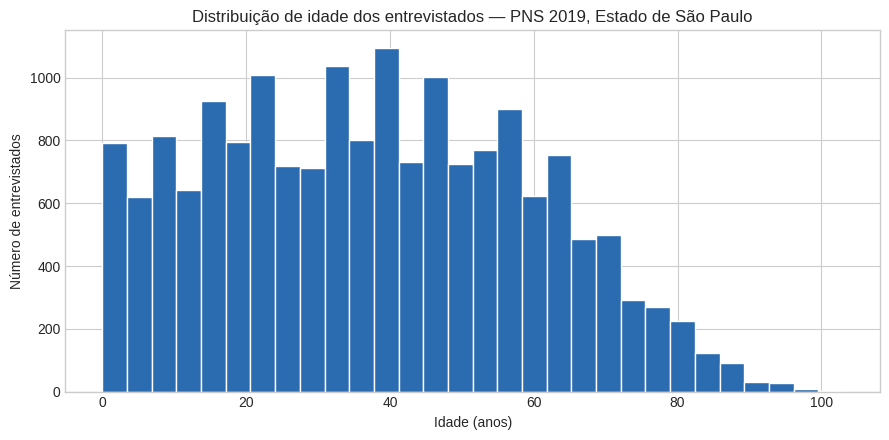

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
df_sp["C008"].dropna().astype(int).plot(kind="hist", bins=30, ax=ax, color="#2b6cb0", edgecolor="white")
ax.set_title("Distribuição de idade dos entrevistados — PNS 2019, Estado de São Paulo")
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Número de entrevistados")
plt.tight_layout()
plt.savefig("data/processed/fig_distribuicao_idade_sp.png", dpi=150)
plt.show()


In [10]:
# Panorama preliminar de prevalência informada (SIM) para as condições de saúde mapeadas
# Atenção: este é só um retrato rápido, sem tratar "não aplicável" nem aplicar peso amostral
# corretamente — o cálculo definitivo de prevalência (ponderado) será feito no notebook de EDA.

condicoes = {
    "Q00201": "Hipertensão",
    "Q03001": "Diabetes",
    "Q068":   "AVC / derrame",
    "Q092":   "Depressão",
    "Q11006": "Outra doença mental",
    "Q124":   "Insuficiência renal crônica",
}

resumo = []
for var, rotulo in condicoes.items():
    respondentes = df_sp[var].notna().sum()
    positivos = (df_sp[var] == "1").sum()
    resumo.append({
        "condicao": rotulo,
        "respondentes": respondentes,
        "positivos_bruto": positivos,
        "percentual_bruto": positivos / respondentes if respondentes else np.nan,
    })

resumo_df = pd.DataFrame(resumo).sort_values("percentual_bruto", ascending=False)
resumo_df


,condicao,respondentes,positivos_bruto,percentual_bruto
0,Hipertensão,6014,1711,0.284503
3,Depressão,6114,691,0.113019
1,Diabetes,5859,620,0.105820
4,Outra doença mental,6114,461,0.075401
2,AVC / derrame,6114,129,0.021099
5,Insuficiência renal crônica,6114,86,0.014066


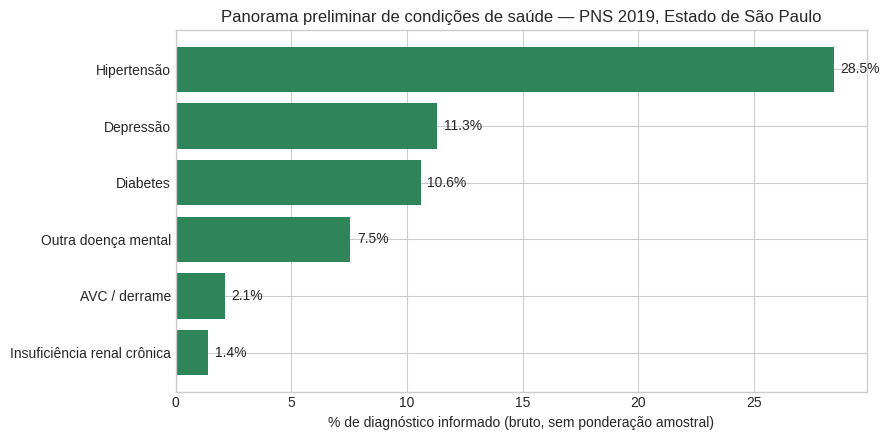

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(resumo_df["condicao"], resumo_df["percentual_bruto"] * 100, color="#2f855a")
ax.set_xlabel("% de diagnóstico informado (bruto, sem ponderação amostral)")
ax.set_title("Panorama preliminar de condições de saúde — PNS 2019, Estado de São Paulo")
ax.invert_yaxis()
for i, v in enumerate(resumo_df["percentual_bruto"] * 100):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.savefig("data/processed/fig_panorama_condicoes_sp.png", dpi=150)
plt.show()


> **Leitura cuidadosa deste gráfico:** os percentuais acima ainda não são as prevalências
> oficiais da PNS — eles não aplicam o peso amostral (`V00281`) nem tratam corretamente os
> códigos de "não aplicável" (que variam por pergunta, ex.: perguntas sobre hipertensão só se
> aplicam a partir de determinada idade). Esse tratamento correto é o foco do próximo notebook.
> Ainda assim, o padrão já é coerente com o que se espera de um levantamento populacional: a
> hipertensão aparece como a condição mais prevalente, seguida da diabetes — condições
> diretamente ligadas à especialidade do nutricionista clínico da clínica parceira.


## 10. Exportação para o próximo notebook

Salvamos dois artefatos:

1. O dataset de **São Paulo, já com entrevistas válidas e tipos corrigidos** — ponto de partida
   do notebook `02_limpeza_e_tratamento.ipynb`;
2. Um pequeno arquivo de **metadados do layout** (`subset_layout`), documentando as decisões de
   leitura tomadas aqui, para rastreabilidade.

Formato escolhido: **Parquet** — mais compacto e rápido de ler que CSV, e preserva os tipos de
dado (evitando o retrabalho de reconverter texto para número a cada notebook).


In [12]:
caminho_saida = PROCESSED_DIR / "pns_2019_sp_bruto.parquet"
df_sp.to_parquet(caminho_saida, index=False)

caminho_layout = PROCESSED_DIR / "layout_variaveis_interesse.parquet"
subset_layout.to_parquet(caminho_layout, index=False)

print("Arquivos exportados:")
print(f" - {caminho_saida}  ({df_sp.shape[0]:,} linhas x {df_sp.shape[1]} colunas)")
print(f" - {caminho_layout}  ({subset_layout.shape[0]} variáveis documentadas)")


Arquivos exportados:
 - data/processed/pns_2019_sp_bruto.parquet  (17,522 linhas x 21 colunas)
 - data/processed/layout_variaveis_interesse.parquet  (21 variáveis documentadas)


## Conclusão e próximos passos

Neste notebook:

- Automatizamos a leitura do layout posicional da PNS 2019 a partir do script SAS oficial do
  IBGE, evitando o mapeamento manual de mais de mil posições de coluna;
- Selecionamos e justificamos 20 variáveis de interesse, conectadas às especialidades da
  clínica parceira (nutrição, psicologia, fisioterapia);
- Lemos o arquivo de largura fixa com ~294 mil registros, convertendo corretamente tipos de
  dado e casas decimais implícitas;
- Validamos a integridade da leitura com checagens de consistência;
- Aplicamos o recorte de escopo do projeto (São Paulo, entrevistas válidas), chegando a uma
  base de trabalho de tamanho gerenciável;
- Fizemos uma primeira leitura exploratória, ainda preliminar, que já aponta hipertensão e
  diabetes como as condições mais informadas — coerente com a literatura epidemiológica.

**Próximo notebook (`02_limpeza_e_tratamento.ipynb`)** vai:
- Recodificar as variáveis categóricas (ex.: `1`/`2` → `"Sim"`/`"Não"`), tratando corretamente
  os casos de "não aplicável";
- Calcular o IMC a partir do peso e altura aferidos, e classificar obesidade;
- Criar faixas etárias alinhadas ao público da clínica (crianças, adultos, idosos);
- Aplicar o peso amostral (`V00281`) para calcular prevalências estatisticamente corretas.
